# Week 4: Multilingual retrieval over official UK guidance

Project: *A Multilingual AI Assistant for Accessing Health, Housing, and Schooling Information*.

This notebook runs on the project pipeline in `src/` instead of copying code into cells:
1. Load the corpus collected in week 3 (38 GOV.UK and NHS.uk pages)
2. Split it into section-aware chunks
3. Build a multilingual search index (multilingual-e5-base + FAISS)
4. Search in five languages
5. Report the week 4 retrieval experiment and its failure cases

In [1]:
import sys, json, pathlib
import pandas as pd
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_colwidth', 90)

## 1. Corpus

Collected by `src/ingest.py` (GOV.UK Content API + NHS.uk pages). Set `RECRAWL = True` to fetch the live pages again.

In [2]:
RECRAWL = False
if RECRAWL:
    import ingest; ingest.main()
pages = pd.DataFrame([json.loads(l) for l in open(ROOT / 'data/processed/pages.jsonl')])
print(len(pages), 'pages, crawled', pages.fetched_at.iloc[0])
pages.groupby(['source', 'domain']).agg(pages=('id', 'count'), words=('words', 'sum'))

38 pages, crawled 2026-10-28T10:08:02+00:00


pages  words
source domain               
GOV.UK health       2   1959
       housing     12  21398
       schools     12   8087
NHS.uk health      12   7570

Publisher dates are not a reliable sign of how current a page is. The eviction guide still says it was published in 2015, but its text already describes the Renters' Rights Act changes from 1 May 2026.

In [3]:
ev = pages[pages.title.str.startswith('Private renting for tenants')].iloc[0]
text = ' '.join(s['text'] for s in ev.sections)
print('public_updated_at:', ev.public_updated_at, '| mentions of "1 May 2026":', text.count('1 May 2026'))

public_updated_at: 2015-10-23 | mentions of "1 May 2026": 3


## 2. Section-aware chunks

One chunk per page section (40-200 words, 40-word overlap). Each chunk starts with `page title - section heading:` so the model sees the context.

In [4]:
import chunk; chunk.main()
chunks = pd.read_csv(ROOT / 'data/processed/chunks.csv')
chunks[['title', 'heading', 'words']].sample(5, random_state=1)

38 pages -> 432 chunks
         pages  chunks  words
domain                       
health      14     101   9889
housing     12     237  21638
schools     12      94   8167
chunk words: median 78 min 40 max 200


,title,heading,words
292,Universal Credit,Your work coach / Attending appointments,88
365,Appointments and bookings at your GP surgery,Evening and Saturday appointments,63
366,Appointments and bookings at your GP surgery,If you're not registered with a GP surgery,58
119,Private renting,If you have a regulated tenancy or an excluded tenancy or licence / Help if you cannot...,87
236,Housing Benefit,Special types of tenancy,68


## 3. Multilingual index

In [5]:
from retrieval import DenseRetriever
e5 = DenseRetriever('intfloat/multilingual-e5-base', chunks.text.tolist())
print('chunks indexed:', e5.index.ntotal)

def show(question, k=3):
    print('Q:', question)
    for i, s in e5.search(question, k):
        c = chunks.iloc[i]
        print(f'  {s:.3f}  {c.title} > {c.heading}\n         {c.url}')
    print()

W1028 15:49:34.347000 31148 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


chunks indexed: 432


In [6]:
show('How do I apply for a primary school place for my child?')   # English
show('Jak zarejestrować się u lekarza rodzinnego?')                 # Polish: how do I register with a GP?
show('Poate proprietarul să mă evacueze fără să-mi dea un motiv?')  # Romanian: can my landlord evict me without a reason?
show('هل يمكن للمالك أن يطردني من المنزل؟')                         # Arabic: can my landlord evict me?
show('میرا گھر چھننے والا ہے، کیا کونسل میری مدد کر سکتی ہے؟')      # Urdu: I am about to lose my home, can the council help?

Q: How do I apply for a primary school place for my child?
  0.905  Apply for a primary school place > Apply for a primary school place
         https://www.gov.uk/apply-for-primary-school-place
  0.891  School admissions > How to apply
         https://www.gov.uk/schools-admissions
  0.890  School admissions > When to apply / Applying for a primary school place
         https://www.gov.uk/schools-admissions

Q: Jak zarejestrować się u lekarza rodzinnego?
  0.796  Register with a GP surgery > Registering someone you care for
         https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/
  0.792  Register with a GP surgery > Important: If a surgery does not accept your registration
         https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/
  0.792  Register with a GP surgery > Changing your address with your current GP surgery / Registering a baby or child
         https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/

Q: Poate prop

## 4. Retrieval experiment

Test set `eval/queries.csv`: 30 questions (10 per domain) in English, Polish, Romanian, Arabic and Urdu = 150 queries. Each question has a gold page and an **answer phrase copied verbatim** from that page.

* **hit@3**: gold page in the top 3 pages
* **ans@3**: a top-3 chunk contains the answer phrase (strict: other wording may also answer)

Four set-ups: BM25 keyword search, the original notebook set-up (e5 on blind 150-word chunks), e5 on section chunks, and MiniLM on section chunks. Run `python eval/evaluate_retrieval.py` to regenerate.

In [7]:
res = pd.read_csv(ROOT / 'results/retrieval_by_lang.csv')
res[res.lang == 'ALL'].drop(columns='lang').set_index('system')

,hit@1,hit@3,mrr@10,ans@3
system,,,,
bm25,0.300,0.400,0.353,0.227
e5_naive150,0.660,0.867,0.773,0.633
e5_sections,0.813,0.960,0.893,0.667
minilm_sections,0.753,0.940,0.846,0.673


In [8]:
per_q = pd.read_csv(ROOT / 'results/retrieval_per_query.csv')
per_q.pivot_table(index='system', columns='lang', values=['hit@3', 'ans@3']).round(2)

ans@3                         hit@3                        
lang               ar    en    pl    ro    ur    ar    en    pl    ro    ur
system                                                                     
bm25             0.10  0.70  0.13  0.10  0.10  0.30  0.97  0.30  0.13  0.30
e5_naive150      0.70  0.73  0.60  0.57  0.57  0.83  0.93  0.93  0.87  0.77
e5_sections      0.73  0.77  0.70  0.67  0.47  0.97  1.00  1.00  0.93  0.90
minilm_sections  0.73  0.80  0.60  0.67  0.57  0.93  0.97  0.93  0.97  0.90

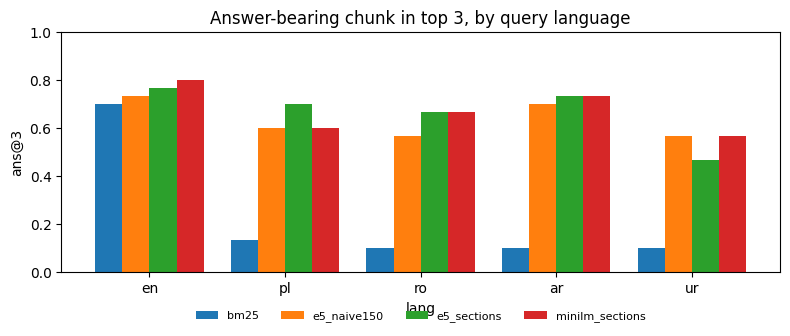

In [9]:
import matplotlib.pyplot as plt
order = ['bm25', 'e5_naive150', 'e5_sections', 'minilm_sections']
langs = ['en', 'pl', 'ro', 'ar', 'ur']
t = per_q.pivot_table(index='lang', columns='system', values='ans@3').loc[langs, order]
ax = t.plot.bar(figsize=(8, 3.5), rot=0, width=0.8)
ax.set_ylabel('ans@3'); ax.set_ylim(0, 1); ax.set_title('Answer-bearing chunk in top 3, by query language')
ax.legend(frameon=False, ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

## 5. Failure cases

**Wrong nation.** For *At what age can my child leave school?* the top chunk is the Scotland rule. The page is right, but the answer would be wrong for someone in England.

In [10]:
show('At what age can my child leave school?')

Q: At what age can my child leave school?
  0.882  School leaving age > Scotland
         https://www.gov.uk/know-when-you-can-leave-school
  0.869  School leaving age > Wales / Northern Ireland / Get financial help with education costs
         https://www.gov.uk/know-when-you-can-leave-school
  0.866  School attendance and absence > When your child can miss school
         https://www.gov.uk/school-attendance-absence



**Right page, not the answering section.** Page-level hit@3 is 0.96 but ans@3 is 0.67. Some of the gap is the strict phrase match (the top chunks for *Can my landlord evict me without giving a reason?* do explain that a reason is now needed), and some is real: the chunk with the answer ranks below other sections of the same page.

In [11]:
e = per_q[per_q.system == 'e5_sections']
print('hit@3 but no answer phrase in top 3:', ((e['hit@3']) & (~e['ans@3'])).sum(), 'of', len(e))
e.groupby('lang')[['hit@3', 'ans@3']].mean().round(2).loc[langs]

hit@3 but no answer phrase in top 3: 44 of 150


,hit@3,ans@3
lang,,
en,1.00,0.77
pl,1.00,0.70
ro,0.93,0.67
ar,0.97,0.73
ur,0.90,0.47


## Next steps (week 5)

* Tag chunks by UK nation and filter to England by default.
* Native-speaker check of the Polish, Romanian, Arabic and Urdu test questions.
* Compare direct multilingual retrieval with translating the question to English first (NLLB-200).
* Try reranking the top 20 chunks to close the gap between hit@3 and ans@3, especially for Urdu.